# الانحدار الخطي ومتعدد الحدود + التقييم واكتشاف Overfitting

يغطّي هذا النوتبوك:
- الجزء 1: أول نموذج Linear Regression على داتاسيت السكري (diabetes).
- الجزء 2: مقاييس التقييم MAE, MSE, RMSE, R² (يدويًا مقابل sklearn).
- الجزء 3: Polynomial Regression على بيانات مصطنعة.
- الجزء 4: منحنى الأداء واكتشاف Overfitting/Underfitting.
- الجزء 5: تطبيق أخير على متغيّر واحد من البيانات الحقيقية.

كل الخلايا منفّذة والرسومات والنتائج ظاهرة، وتحت كل رسمة تفسير.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## الجزء 1 — أول نموذج Linear Regression

In [2]:
data = load_diabetes(as_frame=True)
df = data.frame
print("shape:", df.shape)
df.head()

shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
df.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


### كم متغيّر وما نطاق الـ target؟

In [4]:
print("عدد المتغيرات (Features):", df.shape[1] - 1)   # عمود target ليس Feature
print("أسماء المتغيرات:", [c for c in df.columns if c != 'target'])
print("نطاق target: من", df['target'].min(), "إلى", df['target'].max())

عدد المتغيرات (Features): 10
أسماء المتغيرات: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
نطاق target: من 25.0 إلى 346.0


**ملاحظة:** يوجد **10 متغيّرات** (age, sex, bmi, bp, s1..s6) والهدف `target`
قيمته رقمية تتراوح بين **25 و346** (مقياس تطوّر مرض السكري بعد سنة).

### تقسيم البيانات وتدريب النموذج

In [5]:
X = df.drop(columns='target')
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("تم التدريب على كل المتغيرات.")

Train: (353, 10) | Test: (89, 10)
تم التدريب على كل المتغيرات.


### أول 10 توقعات مقابل القيم الحقيقية

In [6]:
compare = pd.DataFrame({
    "القيمة الحقيقية": y_test.values[:10].round(1),
    "توقّع النموذج": y_pred[:10].round(1),
    "الفرق": (y_test.values[:10] - y_pred[:10]).round(1),
})
compare

,القيمة الحقيقية,توقّع النموذج,الفرق
0,219.0,139.5,79.5
1,70.0,179.5,-109.5
2,202.0,134.0,68.0
3,230.0,291.4,-61.4
4,111.0,123.8,-12.8
5,84.0,92.2,-8.2
6,242.0,258.2,-16.2
7,272.0,181.3,90.7
8,94.0,90.2,3.8
9,96.0,108.6,-12.6


**تفسير:** النموذج قريب أحيانًا وبعيد أحيانًا (فروق تصل لعشرات النقاط)، وهذا
طبيعي لبيانات طبية معقّدة يصعب التنبؤ بها من قياسات محدودة.

## الجزء 2 — مقاييس التقييم

### 1) دوال يدوية لـ MAE و MSE (بدون مكتبات)

In [7]:
def manual_mae(y_true, y_pred):
    return sum(abs(t - p) for t, p in zip(y_true, y_pred)) / len(y_true)

def manual_mse(y_true, y_pred):
    return sum((t - p) ** 2 for t, p in zip(y_true, y_pred)) / len(y_true)

yt = list(y_test.values)
yp = list(y_pred)
print("MAE يدوي:", round(manual_mae(yt, yp), 4))
print("MSE يدوي:", round(manual_mse(yt, yp), 4))

MAE يدوي: 42.7941
MSE يدوي: 2900.1936


### 2) نفس المقاييس عبر sklearn ومقارنتها

In [8]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)
print(f"MAE  = {mae:.4f}")
print(f"MSE  = {mse:.4f}")
print(f"RMSE = {rmse:.4f}")
print(f"R2   = {r2:.4f}")
print("\nمطابقة اليدوي؟ MAE:", np.isclose(mae, manual_mae(yt, yp)),
      "| MSE:", np.isclose(mse, manual_mse(yt, yp)))

MAE  = 42.7941
MSE  = 2900.1936
RMSE = 53.8534
R2   = 0.4526

مطابقة اليدوي؟ MAE: True | MSE: True


**النتيجة:** القيم اليدوية مطابقة تمامًا لنتائج sklearn (MAE ≈ 42.79، MSE ≈ 2900.19،
RMSE ≈ 53.85).

### 3) لو نموذج MAE أقل لكن MSE أعلى؟
هذا ممكن لأن **MSE يعاقب الأخطاء الكبيرة بشدّة** (يربّع الخطأ). فقد يكون النموذج
الأول أخطاؤه صغيرة ومتوسطة (MAE أقل) لكن فيه **أخطاء كبيرة قليلة جدًا** ترفع MSE،
بينما النموذج الآخر أخطاؤه أكبر قليلًا في المتوسط لكن بلا أخطاء ضخمة شاذة.

### 4) تفسير R²
قيمة R² ≈ **0.45** أي أن النموذج يفسّر حوالي **45%** فقط من التغيّر في البيانات —
نموذج **متوسط**: أفضل من التخمين لكنه بعيد عن المثالي (1)، وهذا متوقع لصعوبة التنبؤ
بتطوّر مرض من قياسات خطية بسيطة.

## الجزء 3 — Polynomial Regression على بيانات مصطنعة

In [9]:
np.random.seed(42)
x = np.linspace(-3, 3, 100)
y_syn = 2 * x**2 + 3 * x + np.random.normal(0, 3, size=100)   # علاقة تربيعية + ضجيج
x_col = x.reshape(-1, 1)

### 1) رسم البيانات

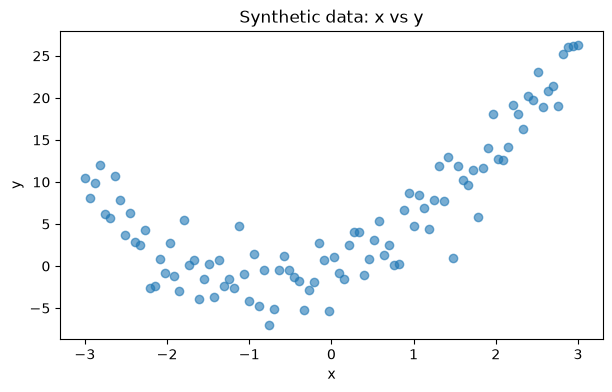

In [10]:
plt.figure(figsize=(7,4))
plt.scatter(x, y_syn, alpha=0.6)
plt.title("Synthetic data: x vs y")
plt.xlabel("x"); plt.ylabel("y")
plt.show()

**تفسير:** الشكل **منحنٍ (Parabola)** وليس خطًا مستقيمًا — علاقة غير خطية واضحة.

### 2) انحدار خطي عادي

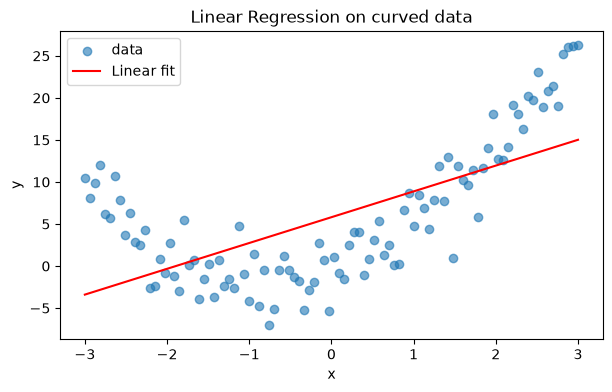

In [11]:
lin = LinearRegression().fit(x_col, y_syn)
plt.figure(figsize=(7,4))
plt.scatter(x, y_syn, alpha=0.6, label="data")
plt.plot(x, lin.predict(x_col), color="red", label="Linear fit")
plt.title("Linear Regression on curved data")
plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.show()

**تفسير:** الخط المستقيم **لا يمثّل البيانات جيدًا** — يمرّ في المنتصف ويتجاهل الانحناء.

### 3) انحدار متعدد الحدود (درجة 2)

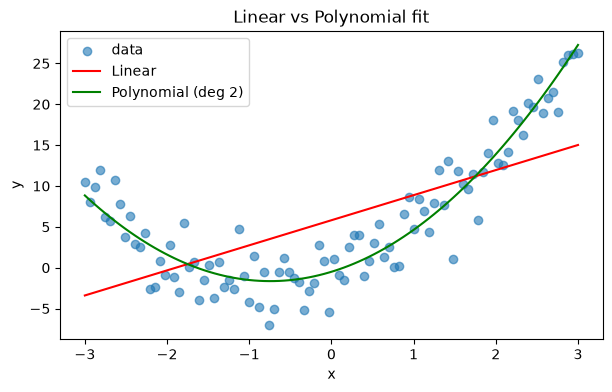

In [12]:
poly = PolynomialFeatures(degree=2)
x_poly = poly.fit_transform(x_col)
poly_model = LinearRegression().fit(x_poly, y_syn)

# ترتيب النقاط للرسم السلس
order = np.argsort(x)
plt.figure(figsize=(7,4))
plt.scatter(x, y_syn, alpha=0.6, label="data")
plt.plot(x, lin.predict(x_col), color="red", label="Linear")
plt.plot(x[order], poly_model.predict(x_poly)[order], color="green", label="Polynomial (deg 2)")
plt.title("Linear vs Polynomial fit")
plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.show()

**تفسير:** المنحنى الأخضر (درجة 2) يتبع شكل البيانات **بدقة أعلى بكثير** من الخط الأحمر.

### 4) مقارنة R²

In [13]:
r2_lin = r2_score(y_syn, lin.predict(x_col))
r2_poly = r2_score(y_syn, poly_model.predict(x_poly))
print(f"R2 الخطي   = {r2_lin:.3f}")
print(f"R2 التربيعي = {r2_poly:.3f}")

R2 الخطي   = 0.424
R2 التربيعي = 0.892


**تفسير:** R² التربيعي (~0.89) أعلى بكثير من الخطي (~0.42)، وهذا منطقي لأن
البيانات أصلًا تربيعية، فالنموذج التربيعي يناسب شكلها.

## الجزء 4 — منحنى الأداء: Overfitting و Underfitting

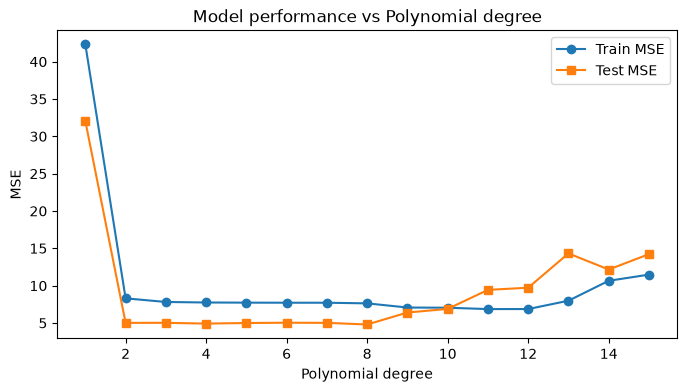

أفضل درجة (أقل Test MSE): 8


In [14]:
x_tr, x_te, y_tr, y_te = train_test_split(x_col, y_syn, test_size=0.3, random_state=42)
degrees = range(1, 16)
train_errors, test_errors = [], []
for d in degrees:
    pf = PolynomialFeatures(degree=d)
    x_tr_p = pf.fit_transform(x_tr)
    x_te_p = pf.transform(x_te)
    m = LinearRegression().fit(x_tr_p, y_tr)
    train_errors.append(mean_squared_error(y_tr, m.predict(x_tr_p)))
    test_errors.append(mean_squared_error(y_te, m.predict(x_te_p)))

plt.figure(figsize=(8,4))
plt.plot(list(degrees), train_errors, "o-", label="Train MSE")
plt.plot(list(degrees), test_errors, "s-", label="Test MSE")
plt.title("Model performance vs Polynomial degree")
plt.xlabel("Polynomial degree"); plt.ylabel("MSE"); plt.legend()
plt.show()
best = list(degrees)[int(np.argmin(test_errors))]
print("أفضل درجة (أقل Test MSE):", best)

**تحليل الرسمة:**
- **Underfitting** عند الدرجة 1: خطأ التدريب والاختبار **كلاهما مرتفع** (النموذج بسيط جدًا).
- **Overfitting** عند الدرجات العالية: خطأ التدريب **منخفض جدًا** بينما خطأ الاختبار
  **يرتفع** (النموذج يحفظ الضجيج ولا يعمّم).
- **أفضل درجة** هي التي يكون عندها Test MSE أدنى ما يمكن (حوالي الدرجة 2)، وهي
  المتوقعة لأن البيانات تربيعية أصلًا.

## الجزء 5 — تطبيق أخير على بيانات حقيقية (متغيّر bmi وحده)

In [15]:
X_bmi = df[['bmi']]
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(X_bmi, y, test_size=0.2, random_state=42)

# 1) خطي
lin_bmi = LinearRegression().fit(Xb_tr, yb_tr)
r2_lin_bmi = r2_score(yb_te, lin_bmi.predict(Xb_te))

# 2) تربيعي
pf = PolynomialFeatures(degree=2)
Xb_tr2 = pf.fit_transform(Xb_tr)
Xb_te2 = pf.transform(Xb_te)
poly_bmi = LinearRegression().fit(Xb_tr2, yb_tr)
r2_poly_bmi = r2_score(yb_te, poly_bmi.predict(Xb_te2))

print(f"R2 خطي (bmi)    = {r2_lin_bmi:.3f}")
print(f"R2 تربيعي (bmi) = {r2_poly_bmi:.3f}")

R2 خطي (bmi)    = 0.233
R2 تربيعي (bmi) = 0.229


**ملاحظة:** على البيانات الحقيقية بمتغيّر `bmi` وحده، الأداء **لم يتحسّن** مع
Polynomial (R² بقي حوالي 0.23 بل تراجع قليلًا)، عكس البيانات المصطنعة. السبب: العلاقة
بين `bmi` و`target` قريبة من الخطية أصلًا وفيها ضجيج كبير، فإضافة درجة أعلى لا تضيف
قدرة تفسيرية حقيقية بل قد تزيد التعقيد بلا فائدة. **الدرس:** Polynomial ليس دائمًا
أفضل — يعتمد على شكل العلاقة الحقيقية في البيانات.